# FigS11d/e unfolded MinCDE profiles

FigS11d is `-MinCDE`; FigS11e is `+MinCDE`. Each panel retains the full
`-1..1` filament axis and displays only individual peak-normalized profiles
plus the dashed filament midpoint. No mean line, center window, legend, or
peak-position panel is drawn.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import SVG, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

os.environ.setdefault("OPENCV_LOG_LEVEL", "ERROR")
try:
    set_matplotlib_formats("svg")
except NotImplementedError:
    pass

try:
    from gear_data_analysis._bootstrap import bootstrap_notebook
except ModuleNotFoundError:
    def _find_repo_root(start: Path) -> Path:
        for candidate in (start, *start.parents):
            if (candidate / ".git").exists() or (
                (candidate / "pyproject.toml").exists()
                and (candidate / "src" / "gear_data_analysis" / "__init__.py").exists()
            ):
                return candidate
        raise FileNotFoundError("Repository root not found from current working directory.")

    REPO_ROOT = _find_repo_root(Path.cwd().resolve())
    SRC_ROOT = REPO_ROOT / "src"
    if str(SRC_ROOT) not in sys.path:
        sys.path.insert(0, str(SRC_ROOT))
    from gear_data_analysis._bootstrap import bootstrap_notebook

REPO_ROOT, SRC_ROOT = bootstrap_notebook(Path.cwd().resolve())
FIGURE_DIR = Path.cwd().resolve()


def preview_svgs(svg_paths):
    for svg_path in svg_paths:
        svg_path = Path(svg_path)
        if not svg_path.exists():
            raise FileNotFoundError(f"Missing SVG output: {svg_path}")
        display(SVG(filename=str(svg_path)))


from gear_data_analysis.peak_position_common import run_figs11de_figure

OUTPUT_DIR = FIGURE_DIR / "02_FigS11de_plot_output"
OUTPUT_SVGS = [OUTPUT_DIR / "FigS11d.svg", OUTPUT_DIR / "FigS11e.svg"]
COMBINED_CSV = OUTPUT_DIR / "FigS11de.csv"


--- Configuration ---
Dataset: FigS11d
Output profile SVG: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d.svg
Output profile CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_profile.csv
Output peak CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_peak.csv
Number of Full-Width Bins: 40
Normalize Intensity: True
Plot mode: individual_only
---------------------

Loaded in-memory stack successfully (contains 17 frames).


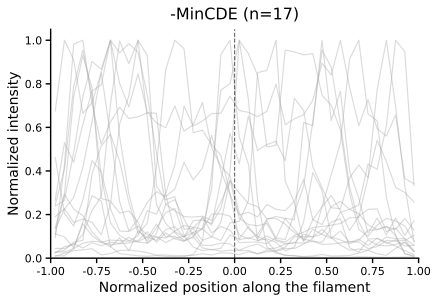


Analysis complete!
Profile SVG saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d.svg
Profile CSV saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_profile.csv
Peak CSV saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_peak.csv
--------------------------------------------------
--- Configuration ---
Dataset: FigS11e
Output profile SVG: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e.svg
Output profile CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_profile.csv
Output peak CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_peak.csv
Number of Full-Width Bins: 40
Normalize Intensity: True
Plot mode: individual_only
---------------------

Loaded in-memory stack successfully (contains 17 frames).


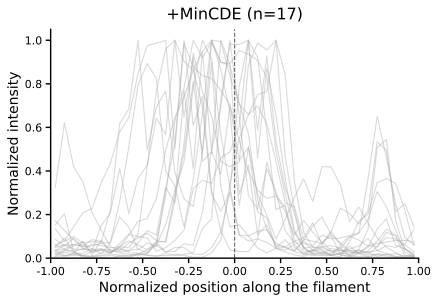


Analysis complete!
Profile SVG saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e.svg
Profile CSV saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_profile.csv
Peak CSV saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_peak.csv
--------------------------------------------------
Combined CSV saved to: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11de.csv
Removed intermediate CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_profile.csv
Removed intermediate CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_profile.csv
Removed intermediate CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11d_peak.csv
Removed intermediate CSV: /Users/yanzhang/git/GEAR_data_analysis/FigS11d:e/02_FigS11de_plot_output/FigS11e_peak.csv


,panel,condition,n_filaments
0,FigS11d,-MinCDE,17
1,FigS11e,+MinCDE,17


In [2]:
analysis_results = run_figs11de_figure(FIGURE_DIR)
pd.DataFrame(
    [
        {
            "panel": result.source_key,
            "condition": result.plot_title,
            "n_filaments": result.frame_count,
        }
        for result in analysis_results
    ]
)

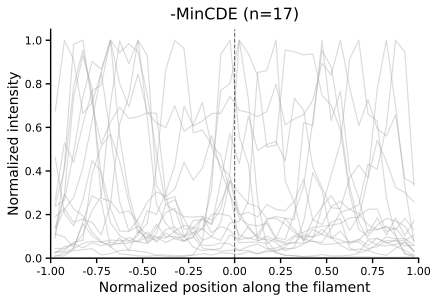

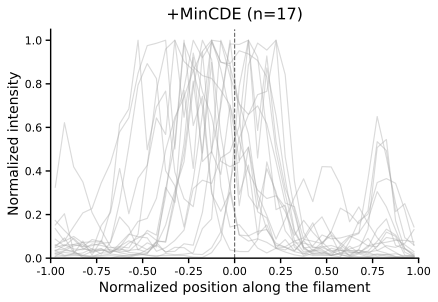

In [3]:
preview_svgs(OUTPUT_SVGS)

In [4]:
combined_table = pd.read_csv(COMBINED_CSV)
profile_table = combined_table.loc[combined_table["table_type"] == "profile"]
profile_table.groupby(
    ["condition_key", "condition_label"], sort=False
).agg(
    profile_bins=("position", "size"),
    position_min=("position", "min"),
    position_max=("position", "max"),
)

,,profile_bins,position_min,position_max
condition_key,condition_label,,,
FigS11d,-MinCDE,40,-0.975,0.975
FigS11e,+MinCDE,40,-0.975,0.975
